In [1]:
from sklearn.datasets import load_iris
iris = load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt
from sklearn import datasets

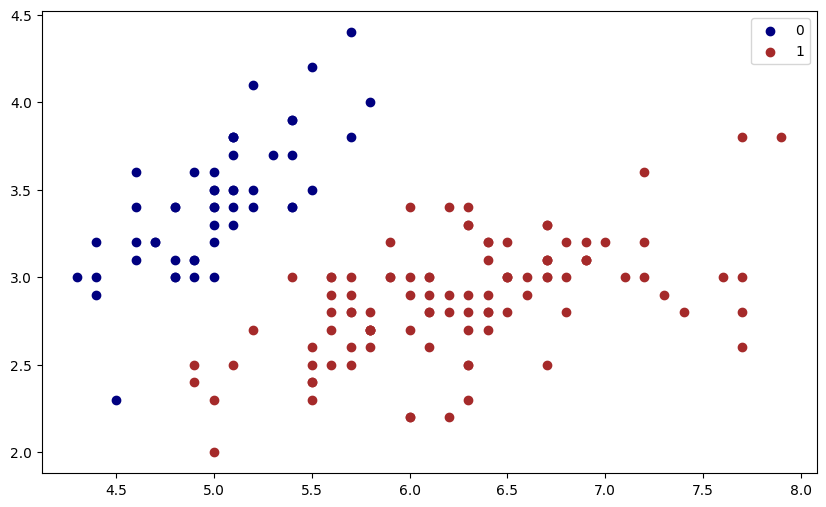

In [4]:
# 데이터 플롯도를 작성
iris = datasets.load_iris()
# iris.data는 꽃밭침의 길이, 꽃받침의 폭, 꽃잎의 길이, 꽃잎의 폭에 대해서의 데이터가 저장되어 있는
# ndarray의 이차원 배열
X = iris.data[:, :2]
# iris.target는 0(=setosa), 1(=versicolor), 2(=virginica)이 저장되어 있는 ndarray의
# 일차원 배열
y = np.where(iris.target!=0, 1, iris.target)
plt.figure(figsize=(10,6))
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='navy', label='0')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='brown', label='1')
plt.legend();

In [6]:
import numpy as np
from sklearn.datasets import load_iris

def add_intercept(X):
    # 다중 선형 회귀를 계산하기 위한 행렬을 작성
    intercept = np.ones((X.shape[0], 1))
    return np.concatenate((intercept, X), axis=1)

def sigmoid(z):
    # 시그모이드 함수
    return 1 / (1 + np.exp(-z))

def cross_entropy(h, y):
    # 교차 엔트로피 오차
    return (-y * np.log(h) - (1 - y) * np.log(1 - h)).mean()

def predict_prob(X, theta):
    # 교차 엔트로피 오차가 가장 작은 최신의 가중치를 이용하여 X의 데이터로부터 확률의 예측값을 출력
    X = add_intercept(X)
    return sigmoid(np.dot(X, theta))

def predict(X, theta):
    # 시그모이드 함수에 의해 출력된 확률의 예측값에서 0.5이상은 1, 0.5 이하는 0으로 분류한 라벨을 출력
    return predict_prob(X, theta).round()
    

In [7]:
# 오차를 보면서 lr을 조정한다
# 학습률 (learning rate)를 조정하면서 가중치를 갱신하고, 교차 엔드로피 오차가 없이 한없이 0에 가까워질 떄의
# 학습률을 찾는다
lr=0.1
iter_nums = 300000

X = add_intercept(X)

# 가중치의 초기화
theta = np.zeros(X.shape[1])

# 최급 강하법
for i in range(iter_nums):
    z = np.dot(X, theta)
    h = sigmoid(z)

    # 기울기(=편미분항)을 계산
    gradient = np.dot(X.T, (h - y)) / y.size
    # 가중치를 갱신
    theta = theta - lr * gradient

    # 교차 엔드로피 오차를 저장
    loss = cross_entropy(h, y)
    if(i % 10000 -- 0):
        # 교차 엔드로피 오차를 출력
        print(f'loss: {loss} \t')
iris = load_iris()
X = iris.data[:, :2]
predict_prob(X, theta)
# 확률값을 사용하여 분류 라벨을 예측
predict(X, theta)

    

loss: 0.6106904453410645 	
loss: 0.6049984866545791 	
loss: 0.5996685296955178 	
loss: 0.5944149352382619 	
loss: 0.589235632119298 	
loss: 0.5841296571438626 	
loss: 0.579096048919403 	
loss: 0.5741338445585796 	
loss: 0.5692420804985813 	
loss: 0.5644197933509465 	
loss: 0.5596660207171711 	
loss: 0.5549798019670644 	
loss: 0.5503601789797653 	
loss: 0.5458061968476117 	
loss: 0.5413169045431868 	
loss: 0.536891355549965 	
loss: 0.5325286084570935 	
loss: 0.5282277275189174 	
loss: 0.5239877831799534 	
loss: 0.5198078525660704 	
loss: 0.5156870199427076 	
loss: 0.5116243771410083 	
loss: 0.5076190239527915 	
loss: 0.503670068495325 	
loss: 0.499776627546885 	
loss: 0.49593782685412047 	
loss: 0.4921528014122478 	
loss: 0.48842069571912117 	
loss: 0.48474066400421995 	
loss: 0.481111870433608 	
loss: 0.477533489291903 	
loss: 0.4740047051422988 	
loss: 0.4705247129656635 	
loss: 0.4670927182797294 	
loss: 0.4637079372393679 	
loss: 0.46036959671892874 	
loss: 0.45707693437759794 	
los

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [8]:
import matplotlib.pyplot as plt
import numpy as np

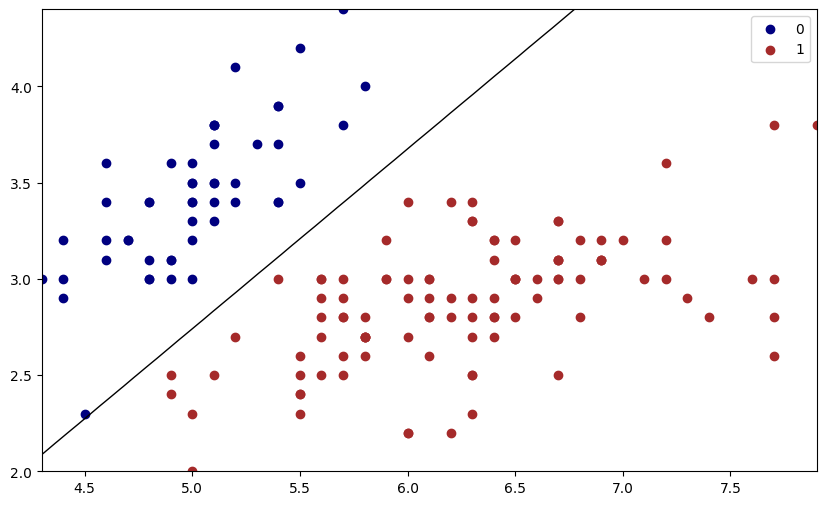

In [10]:
# 데이터를 플롯
plt.figure(figsize=(10, 6))
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='navy', label='0')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='brown', label='1')
plt.legend()

# x축, y축 스케일 정의 
x_min, x_max = X[:, 0].min(), X[:, 0].max()
y_min, y_max = X[:, 1].min(), X[:, 1].max()

# 격자(Meshgrid) 생성
xx, yy = np.meshgrid(np.linspace(x_min, x_max), np.linspace(y_min, y_max))
grid = np.c_[xx.ravel(), yy.ravel()]

# 분류 경계선 표시 
probs = predict_prob(grid, theta).reshape(xx.shape)
plt.contour(xx, yy, probs, [0.5], linewidths=1, colors='black')
plt.show()

In [11]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
iris = load_iris()
x = iris.data[:, :2]
y = np.where(iris.target!=0, 1, iris.target)
model = LogisticRegression()
model.fit(X, y)
model.predict(X)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])